Public-contract revision 2026-10-29

V2 defines the spatial anisotropic TV noise-compatible video class, with all15original per-exposure residual budgets unchanged. Each14-frame burst TV is the sum of absolute neighboring row and column differences across all frames, no temporal derivative or extra positivity. Its independent feasible standard TV plus relative1e-8 allowance supplies the public bound. A100-step independent measurement-nullspace projected TV descent on burst0 reduces TV12573.74257 to10323.04290 while preserving its observation, and passes; other14bursts remain identified existing method results. Temporal reversal fails. No actual video truth exists. Earlier array-agreement plots and metric tables are historical v1 reproducibility diagnostics. Current standalone v2 acceptance uses the public physical/regularity class. Source algorithm unchanged; current metric interface executes without indexing removed keys.

# Recovering a real high-speed movie from coded exposures

## Problem

A moving aperture encodes fourteen successive grayscale scene instants into each camera exposure. Recover **all210chronological256×256frames** from the complete fifteen-exposure rotating-wheel recording. This is temporal inversion rather than wavelength unmixing or ordinary image denoising. A single exposure is severely underdetermined; a spatial image prior resolves only part of the null space.

## Data

Inputs are real author-provided camera measurements and independently calibrated, real-valued masks. They are not synthetic coded exposures. Every native pixel, exposure and calibrated code is retained. Absolute frame period and radiometric calibration are unavailable, so time is shown by relative frame index and intensity by the supplied linear scale. **Independent high-speed video GT is unavailable**. Original reconstructions below are method references, never truth.

In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file();sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import observed_residuals
from src.visualization import review_figures
data=load_data(ROOT/'data/raw_data.npz')
print({key:dict(shape=value.shape,dtype=str(value.dtype),minimum=float(value.min()),maximum=float(value.max())) for key,value in data.items()})
print('raw SHA256',hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())


{'mask': {'shape': (14, 256, 256), 'dtype': 'float64', 'minimum': 0.0, 'maximum': 1.0}, 'observations': {'shape': (15, 256, 256), 'dtype': 'float64', 'minimum': 0.0, 'maximum': 4.62}}
raw SHA256 e40cbcf531fa46afc4ab7a0e4593c52ccb89494294fa7f4401bc90cd2e892749


## Physics

Let $X_t(p)$ be radiance at detector pixel $p$ in temporal slice $t$, $C_t(p)$ a calibrated effective code and $Y(p)$ a measured exposure. In internal mask order,

$$A(X)(p)=\sum_{t=0}^{13}C_t(p)X_t(p),\qquad A^{\mathsf T}(Y)_t(p)=C_t(p)Y(p),\qquad AA^{\mathsf T}(Y)(p)=E(p)Y(p),\quad E(p)=\sum_{t=0}^{13}C_t(p)^2.$$

Measured exposures also contain noise/model error. The aperture sweep reverses every second exposure: internal mask order is reversed to chronology on zero-based odd bursts. Effective codes already contain exposure normalization; no additional integration factor is applied. The diagonal measurement-space normal operator avoids a dense sensing matrix, while the14-to1temporal mapping leaves a large null space.

## Method

The chosen author algorithm is accelerated GAP-TV with100outeriterations and5inner spatial-TV steps per projection, with relaxation1 and TVweight0.07. It starts from the calibrated acquisition adjoint. For each outer iteration, accumulated measurement $U$ updates as $U\leftarrow U+Y-A(X)$, then $X\leftarrow X+A^{\mathsf T}[(U-A(X))/E]$, followed by the finite TV operation. The updated accumulator is used, matching the actual source convention.

Spatial forward differences use zero-flux boundaries. Horizontal and vertical dual arrays begin at zero on each TV call; each inner step averages the two directional primal estimates, updates the duals by one fifth of the new spatial difference, and clips to ±0.035. The returned primal precedes the final dual update. This is the original finite separable-direction operation, **not an exact isotropic/spatiotemporal proximal solve**. There is no temporal TV, positivity constraint, learned denoiser or global-convergence claim.

The following two cells each reconstruct the entire real acquisition actively. ADMM-TV200 is an independent full comparison with its own adjoint initialization, gamma1and the same TVsettings; it returns the original prescribed primal before denoising, not its auxiliary variable. A longer timeout is justified by the15×100/200×5full-resolution computation. References are not loaded until both fresh reconstructions finish.

In [2]:
start=time.perf_counter()
fresh_gap_result,gap_diagnostics=reconstruct(data,method='gap')
gap_runtime=time.perf_counter()-start
fresh_gap=fresh_gap_result['reconstruction'][0]
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh_gap_result)
print('FRESH complete GAP100:',json.dumps(dict(runtime_s=gap_runtime,shape=list(fresh_gap.shape),range=[float(fresh_gap.min()),float(fresh_gap.max())])))


FRESH complete GAP100: {"runtime_s": 318.59303499991074, "shape": [210, 256, 256], "range": [-0.2011248810348068, 3.572398379131931]}


In [3]:
start=time.perf_counter()
fresh_admm_result,admm_diagnostics=reconstruct(data,method='admm')
admm_runtime=time.perf_counter()-start
fresh_admm=fresh_admm_result['reconstruction'][0]
print('FRESH complete ADMM200:',json.dumps(dict(runtime_s=admm_runtime,shape=list(fresh_admm.shape),range=[float(fresh_admm.min()),float(fresh_admm.max())])))


FRESH complete ADMM200: {"runtime_s": 698.0479758000001, "shape": [210, 256, 256], "range": [-0.09815053724749606, 1.5234421223451176]}


## Results

All fifteen exposures and every reconstructed frame are visualized. Figure grayscale limits [0,1] are **display only**; negative values and overshoots remain in the stored estimates and are quantified. The frame contact sheet shows all210chronological results, including the reversed aperture sweeps.

The original method measurements below come from independently executed author code on the exact bound masks/observations: GAP100andADMM200. They are distinct from published paper tables and from these fresh local measurements. No actual high-speed video truth is available, so no PSNR or physical recovery accuracy is invented. Judge requires all210frames to satisfy reference agreement and all15exposures to satisfy forward consistency. A small residual alone cannot resolve null-space uncertainty.

Independent Judge for the fresh GAP: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "minimum_frame_ncc": 0.9999999999999997,
    "maximum_frame_nrmse": 4.4311544115960584e-17,
    "relative_observation_residual_0": 0.0005178242826787696,
    "relative_observation_residual_1": 0.0004953263411424744,
    "relative_observation_residual_2": 0.0005175605554493542,
    "relative_observation_residual_3": 0.0005957393764131484,
    "relative_observation_residual_4": 0.0005459558613848471,
    "relative_observation_residual_5": 0.0004882579835874144,
    "relative_observation_residual_6": 0.00044822806831977985,
    "relative_observation_residual_7": 0.00046320573568353325,
    "relative_observation_residual_8": 0.0004232182662252014,
    "relative_observation_residual_9": 0.0004562532224476714,
    "relative_observation_residual_10": 0.00043485411005604244,
    "relative_observation_residual_11": 0.0004752780757832663,
    "relative_observation_residual_12": 0.0005207367654151935,


fresh_gap100 {"minimum_ncc": 0.9999999999999997, "maximum_range_nrmse": 4.4311544115960584e-17, "maximum_absolute_to_own_original": 2.6645352591003757e-15, "observed_residual_by_burst": [0.0005178242826787696, 0.0004953263411424744, 0.0005175605554493542, 0.0005957393764131484, 0.0005459558613848471, 0.0004882579835874144, 0.00044822806831977985, 0.00046320573568353325, 0.0004232182662252014, 0.0004562532224476714, 0.00043485411005604244, 0.0004752780757832663, 0.0005207367654151935, 0.0005858923736799756, 0.0006131987730719407], "fraction_negative": 0.0035992576962425595, "fraction_above1": 3.574916294642857e-05}


fresh_admm200 {"minimum_ncc": 0.9999999999999996, "maximum_range_nrmse": 7.84150894565524e-17, "maximum_absolute_to_own_original": 2.6645352591003757e-15, "observed_residual_by_burst": [0.01557116846740403, 0.014248112527801554, 0.01637689117801352, 0.015756008905569652, 0.01676428979660097, 0.01544802464182906, 0.017172072840714328, 0.01601123840111397, 0.016731418805222137, 0.015647579322249427, 0.017102339685397747, 0.015371134929479998, 0.017068993674409186, 0.015271350957679312, 0.0167053890595903], "fraction_negative": 0.004479108537946429, "fraction_above1": 0.00022517613002232144}


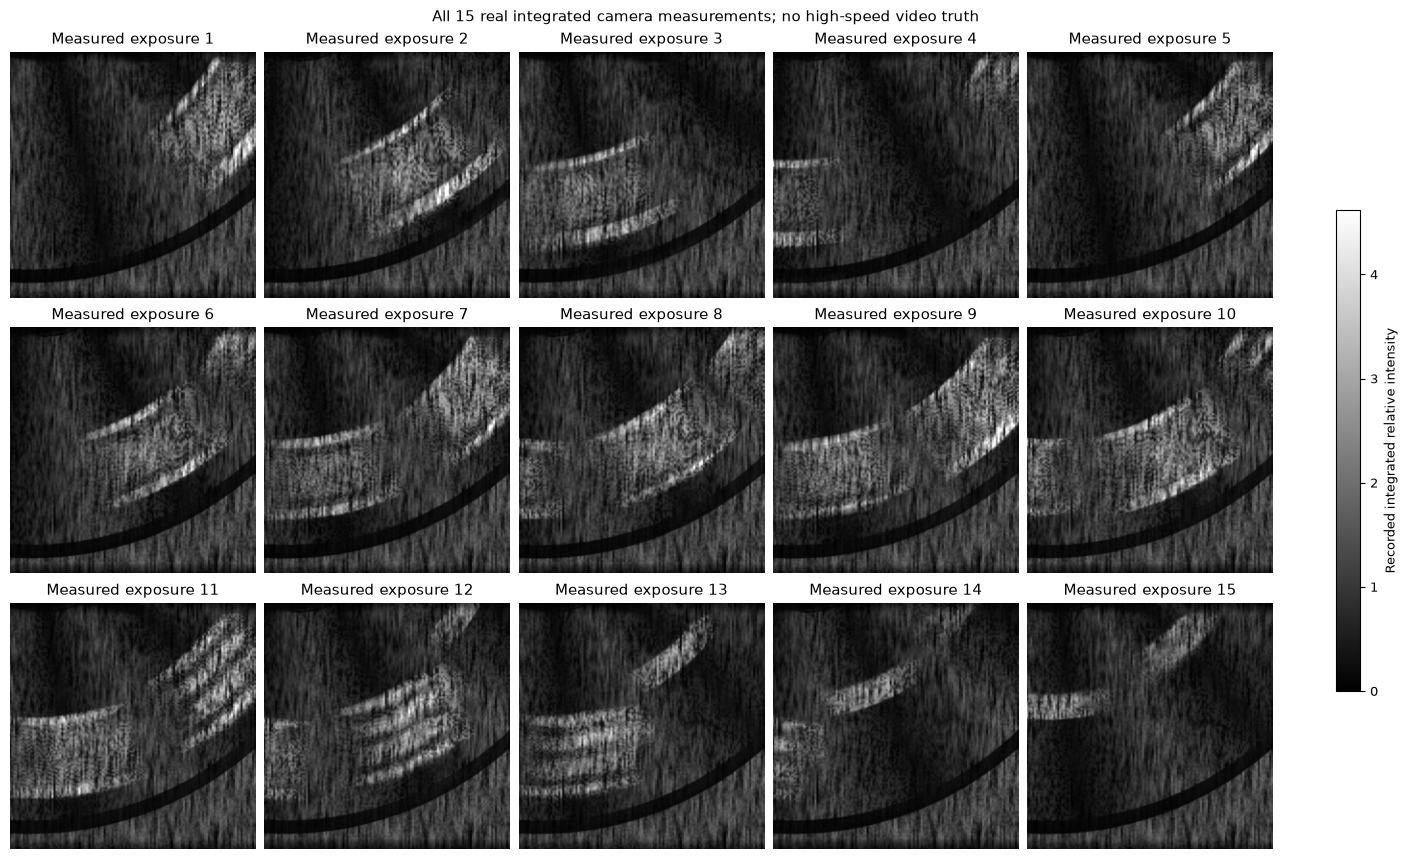

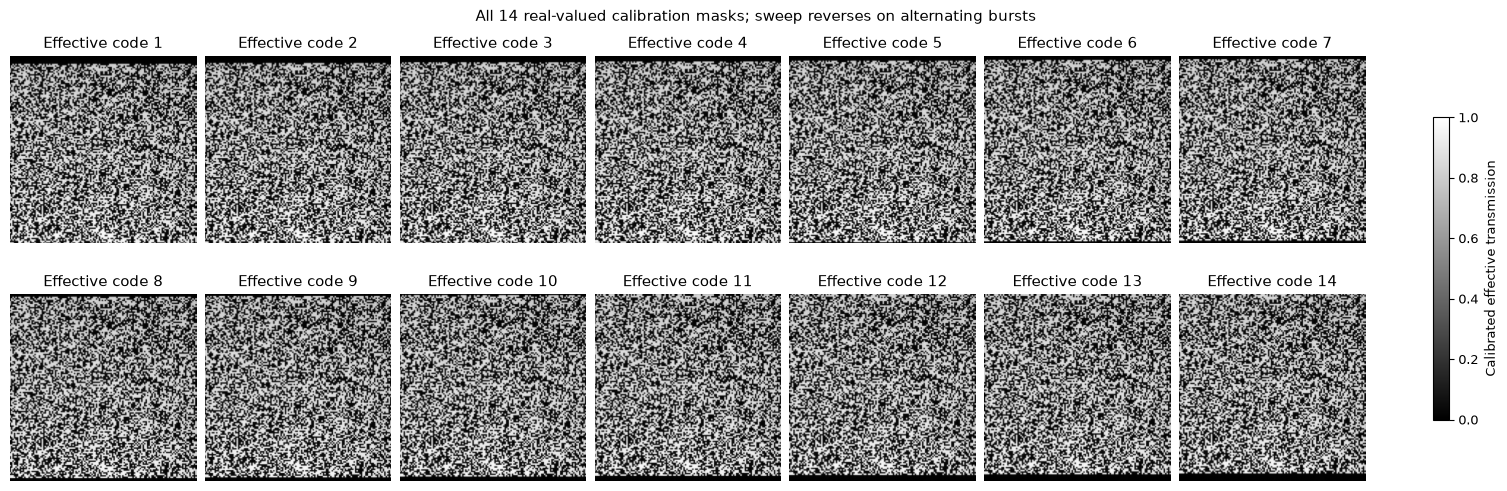

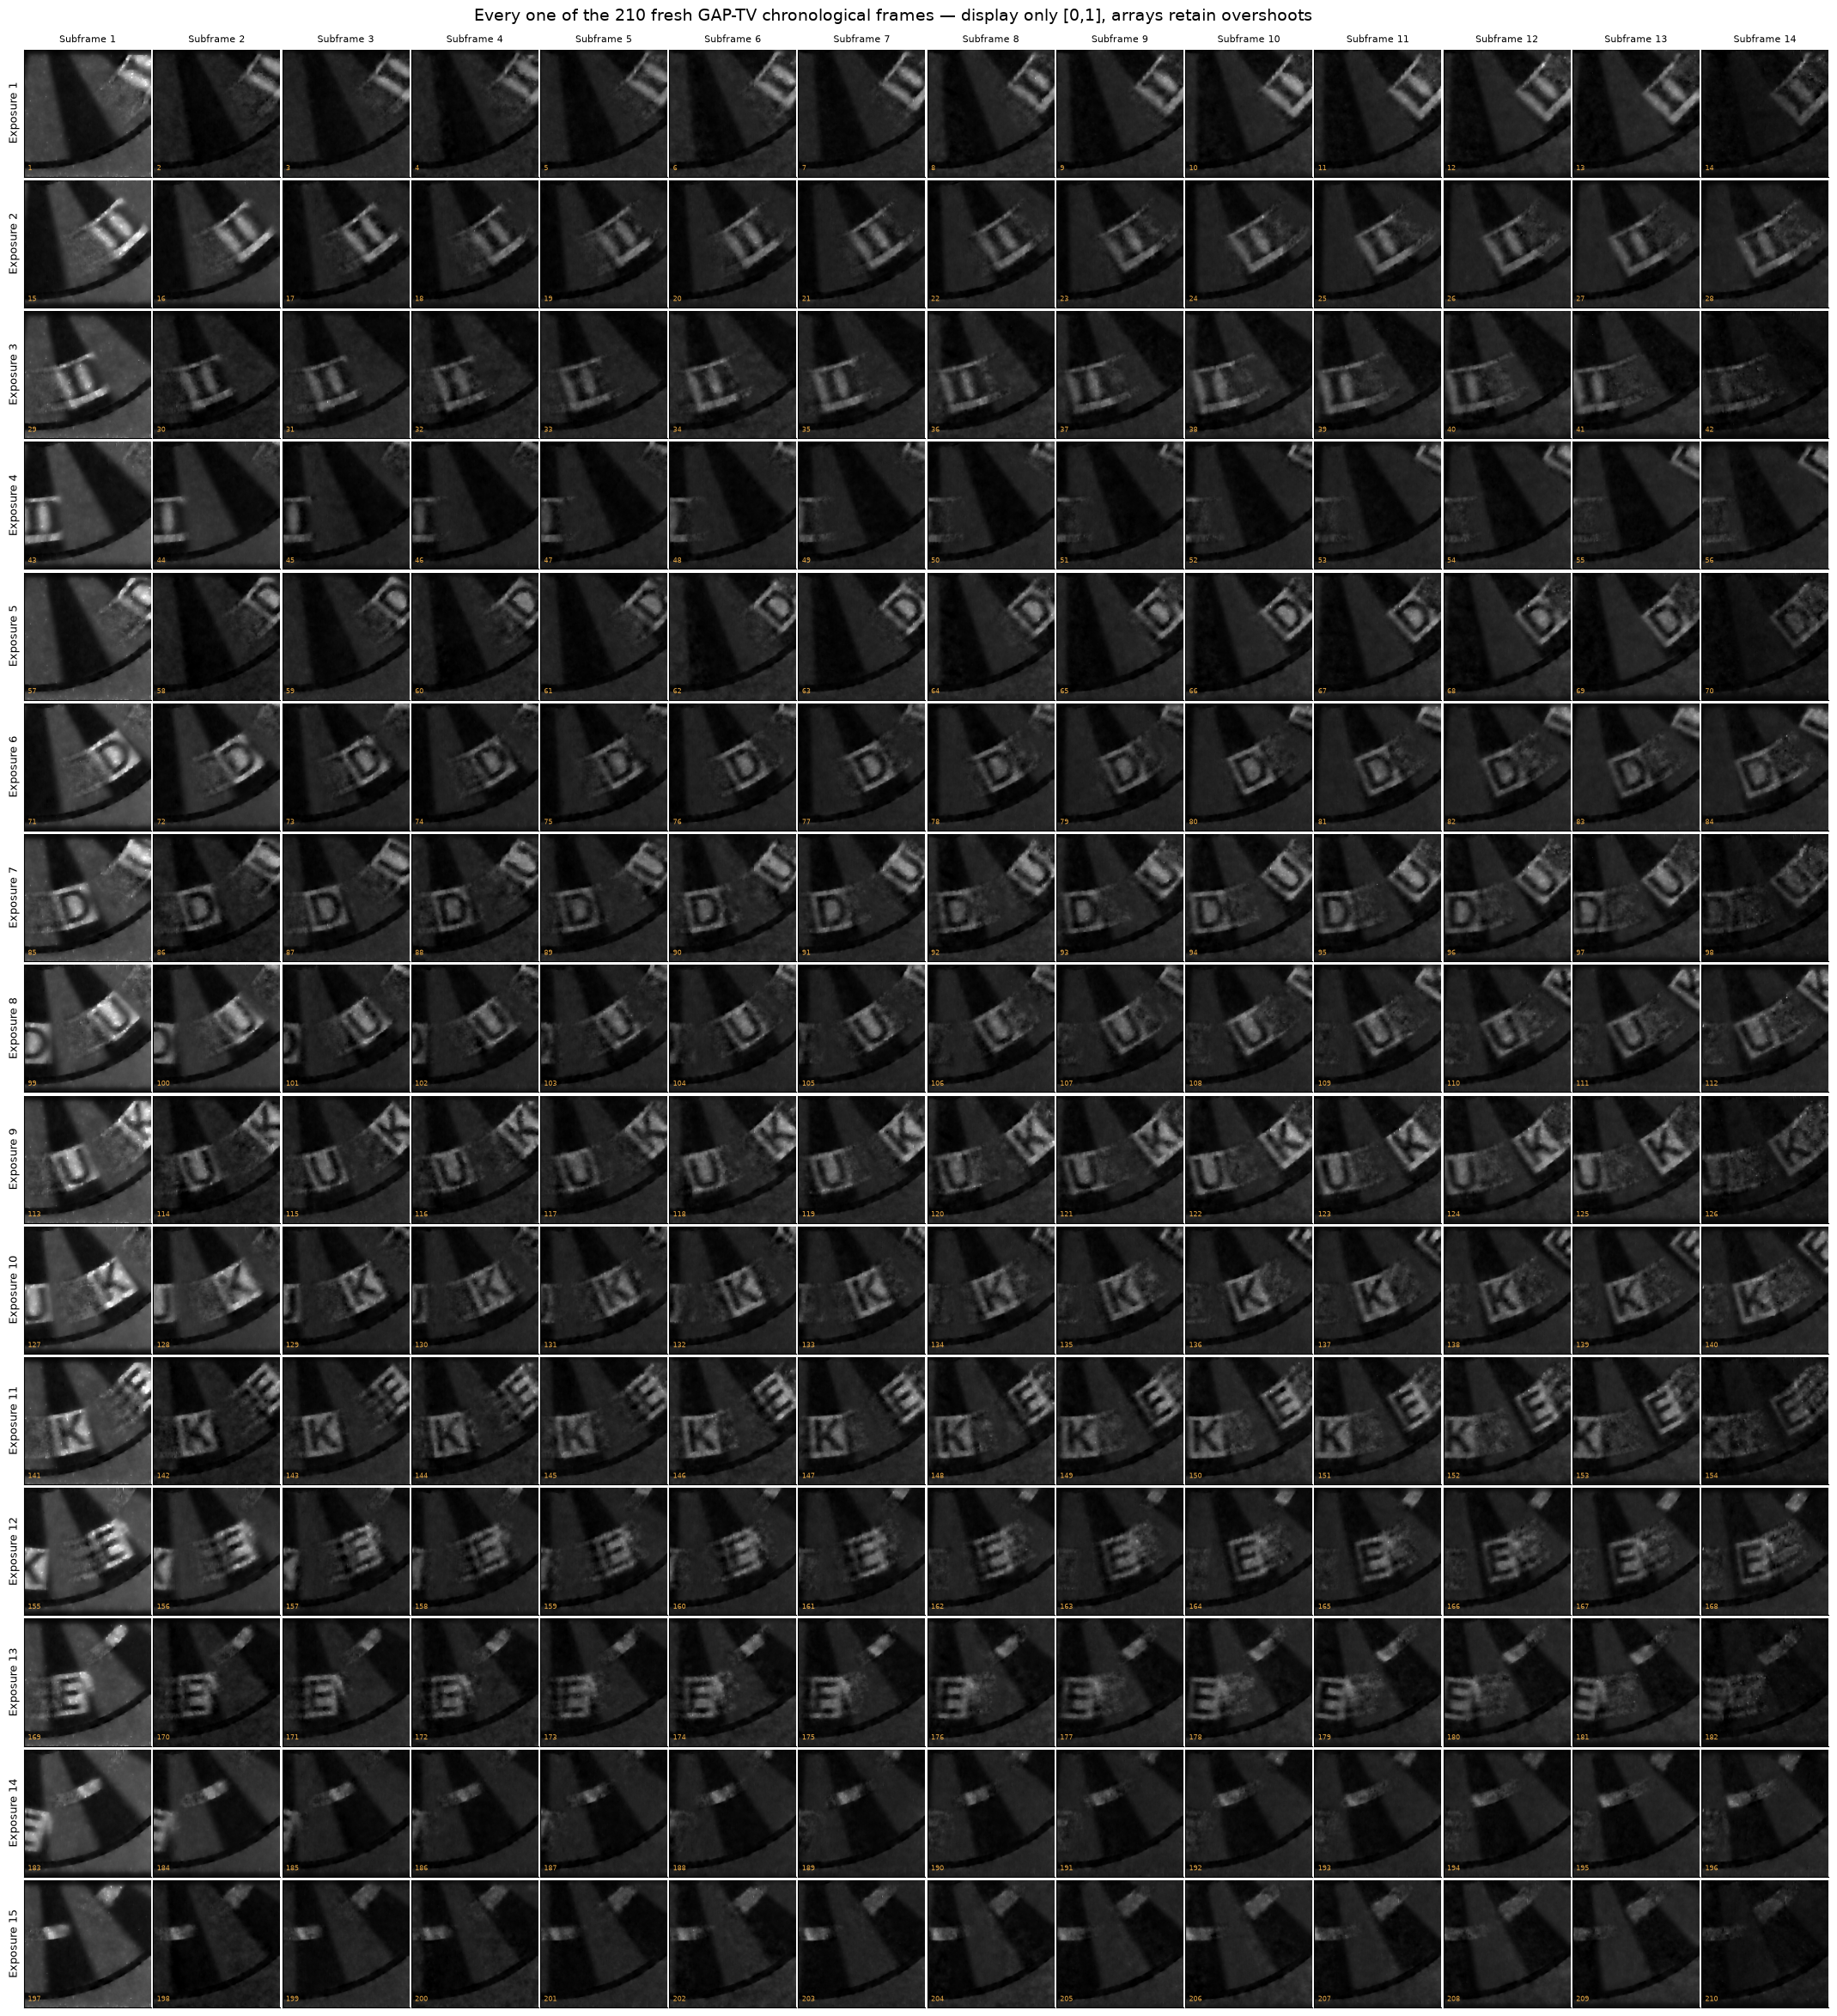

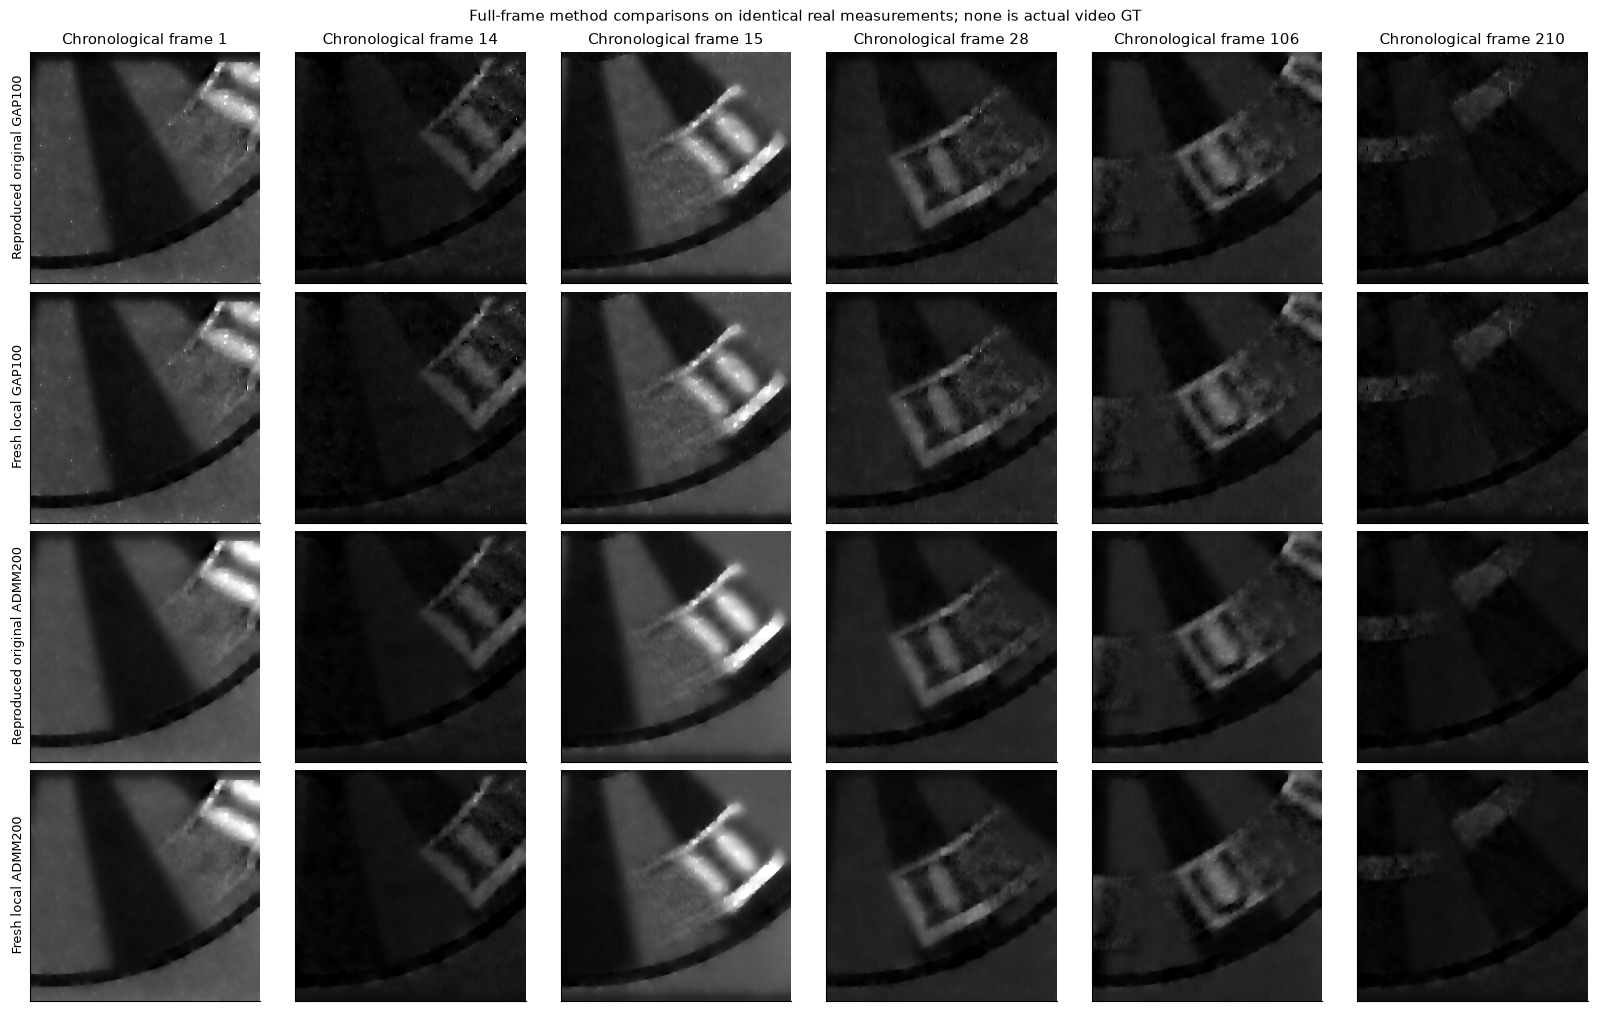

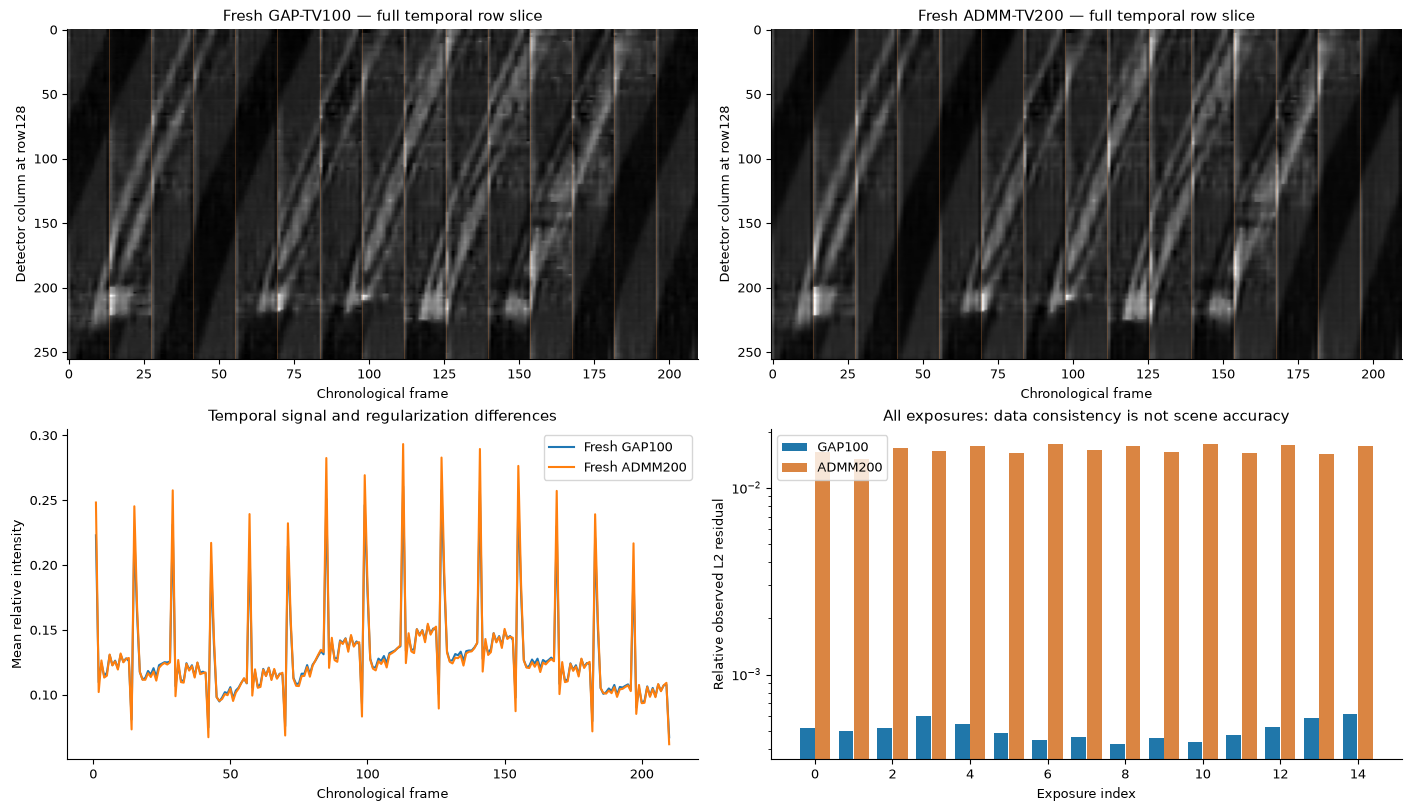

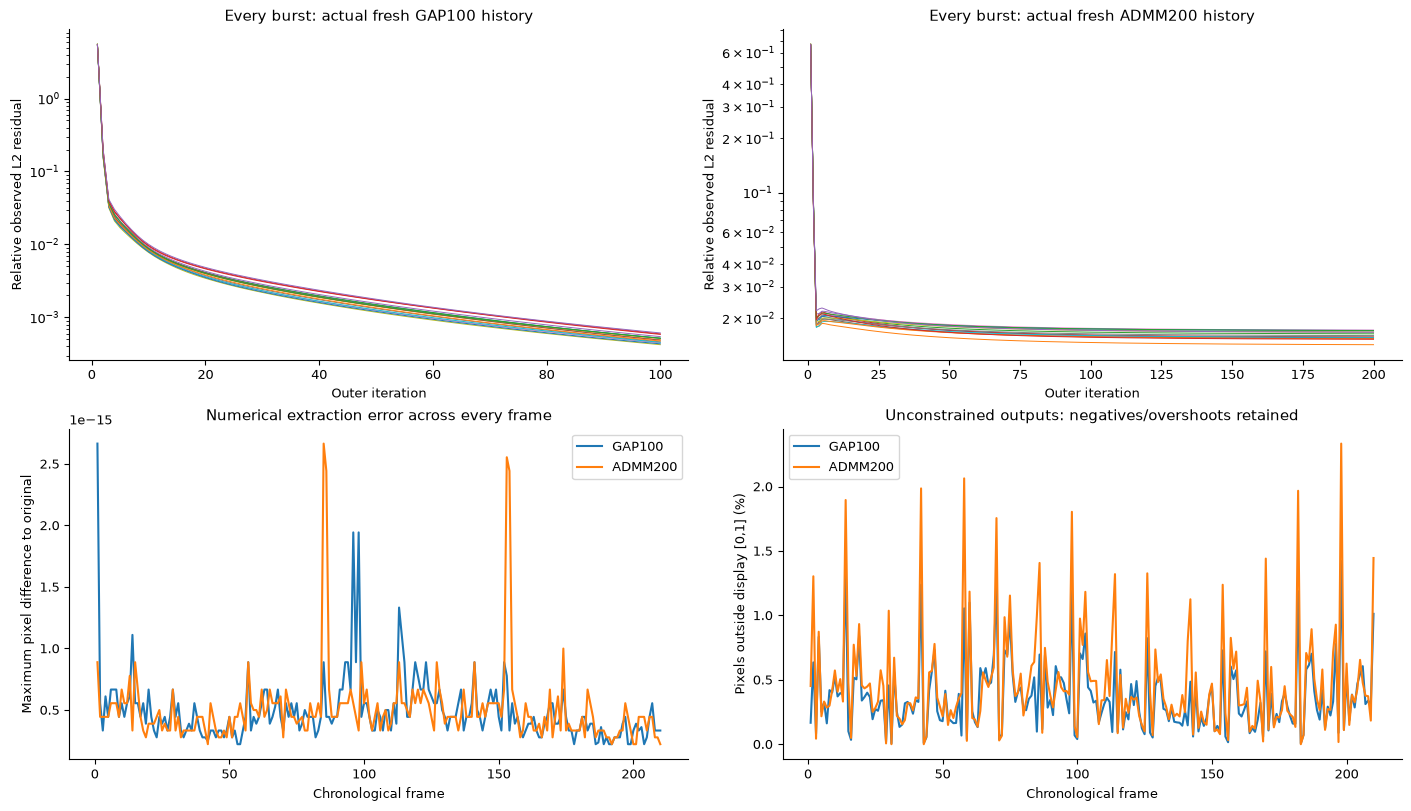

In [4]:
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as z:original_gap=z['reconstruction'][0].copy()
with np.load(ROOT/'notebooks/reference_outputs/upstream_admm200.npz',allow_pickle=False) as z:original_admm=z['reconstruction'][0].copy()
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz');assert report['passed'],report
print('Independent Judge for the fresh GAP:',json.dumps(report,indent=2))
measurements={}
for label,movie,original,runtime in [('fresh_gap100',fresh_gap,original_gap,gap_runtime),('fresh_admm200',fresh_admm,original_admm,admm_runtime)]:
    metrics=np.array([judge.frame_metrics(p,r) for p,r in zip(movie,original)])
    maximum=float(np.max(abs(movie-original)));assert maximum<=1e-7,(label,maximum)
    residual=observed_residuals(movie,data['observations'],data['mask'])
    measurements[label+'_frame_metrics']=metrics;measurements[label+'_observation_residual']=residual;measurements[label+'_runtime_s']=np.asarray(runtime)
    print(label,json.dumps(dict(minimum_ncc=float(metrics[:,0].min()),maximum_range_nrmse=float(metrics[:,1].max()),maximum_absolute_to_own_original=maximum,observed_residual_by_burst=residual.tolist(),fraction_negative=float(np.mean(movie<0)),fraction_above1=float(np.mean(movie>1)))))
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_notebook_measurements.npz',**measurements)
figures=review_figures(data,fresh_gap,fresh_admm,original_gap,original_admm,gap_diagnostics,admm_diagnostics)
for number,fig in enumerate(figures,1):
    if os.environ.get('IMAGING_REVIEW_EXPORT_DIR'):
        dest=Path(os.environ['IMAGING_REVIEW_EXPORT_DIR']);dest.mkdir(parents=True,exist_ok=True);fig.savefig(dest/f'figure_{number:02d}.png',dpi=130)
    display(fig);plt.close(fig)


## Conclusion

The cleaned local mathematics actively recovers the complete real210-frame sequence with both selected classical methods and matches the independently run original implementations. GAP achieves tighter exposure consistency; ADMM produces a different smoothing/fit balance. Full-frame overshoots, temporal structure, convergence histories and every exposure residual are visible rather than suppressed by a favorable crop or gain correction.

Neither method-reference agreement nor data consistency proves the unknown true movie. Real camera noise, imperfect modulation, finite TV inner iterations and temporal null-space ambiguity limit interpretation. The selected2016classical method uses the2020author code and a separate author2019real-data bundle; this is not an unchanged2019DeSCI/admm_resreproduction. Unrun deep denoisers are outside the selected scope and are not filled with surrogate results. The2020paper's revised proof is acknowledged; no obsolete global-convergence claim is made.

Sources: Yuan, ICIP2016, DOI10.1109/ICIP.2016.7532817; Yuan etal., CVPR2020/arXiv2003.13654v2; Llull etal., OpticsExpress2013, DOI10.1364/OE.21.010526. Original source/data redistribution permissions remain unverified; this package is internal benchmark review material. Exact revisions, data hashes, actual original/fresh executions and independent numerical/physical tests are recorded in the maintainer validation evidence.